# 01 — EDA: the clean training table

Exploration of the Phase 1c clean table (HANDOFF section 9). Pipeline code lives in `src/`;
this notebook only reads. Re-run top to bottom after any sweep:
`uv run jupyter execute notebooks/01_eda.ipynb` or via your editor.

Executed 2026-10-24 against `data/housing.db`.

In [1]:
import matplotlib.pyplot as plt
import pandas as pd

from housing.db import connect
from housing.model.dataset import BOOLEANS, CATEGORICALS, NUMERICS, TARGET, load_training

pd.set_option("display.width", 120)
conn = connect()
df, report = load_training(conn)          # deduped: one row per unit and price band
all_ads, _ = load_training(conn, dedup=False)
print(report)
print(f"without dedup: {len(all_ads)} ads")

clean table: kept 1862 rows; dropped 545 (no_price=52, no_location=0, out_of_region=109, wanted_ad=5, per_term_price=0, bad_bedrooms=0, no_target=0, target_out_of_range=19, room_price_out_of_range=16, duplicates=344); bathrooms set NA on 0
without dedup: 2206 ads


## What the cleaning kept and dropped

Every drop rule is counted above; `duplicates` is reposts collapsed to the newest ad per unit (HANDOFF section 5 dedup with the 5-percent price-band rule).

In [2]:
df.groupby("unit_type", dropna=False)[TARGET].describe().round(0)[["count", "mean", "50%", "min", "max"]]

,count,mean,50%,min,max
unit_type,,,,,
1bed,408.0,1648.0,1650.0,375.0,2600.0
2bed,527.0,998.0,975.0,495.0,2000.0
3plus,326.0,824.0,833.0,300.0,1475.0
house,207.0,950.0,883.0,500.0,2850.0
room,351.0,849.0,800.0,390.0,1800.0
studio,43.0,1446.0,1400.0,1050.0,3000.0


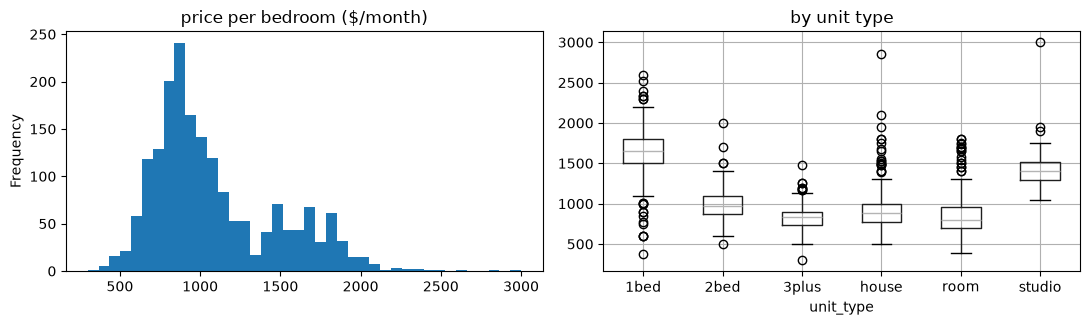

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
df[TARGET].plot.hist(bins=40, ax=axes[0], title="price per bedroom ($/month)")
order = df.groupby("unit_type")[TARGET].median().sort_values().index
df.boxplot(column=TARGET, by="unit_type", ax=axes[1], positions=range(len(order)))
axes[1].set_title("by unit type"); plt.suptitle(""); plt.tight_layout()

## Where the listings are

,count,median
neighbourhood,,
N2G,174,1275.0
N2J,164,1031.0
N2B,44,1000.0
N2T,46,1000.0
N2H,146,996.0
N2K,53,983.0
N2A,110,962.0
N2C,58,936.0
N2E,147,933.0


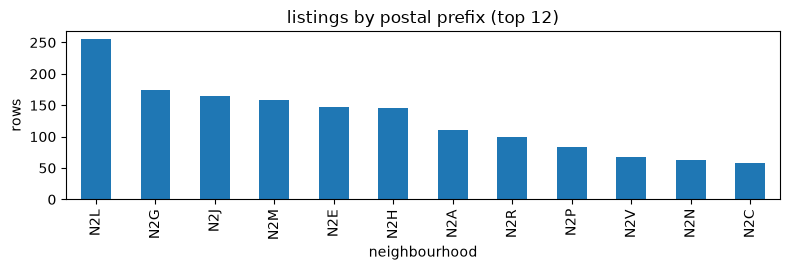

In [4]:
top = df["neighbourhood"].value_counts().head(12)
ax = top.plot.bar(figsize=(8, 2.8), title="listings by postal prefix (top 12)")
ax.set_ylabel("rows"); plt.tight_layout()
df.groupby("neighbourhood")[TARGET].agg(["count", "median"]).query("count >= 30").sort_values("median", ascending=False).round(0).head(10)

## Feature effects, first look

Medians, not causal claims. Lease term and walk time are the student-market signals HANDOFF cares about.

In [5]:
for col in ("lease_term", "furnished", "utilities_included", "building_type"):
    line = df.groupby(col, dropna=False)[TARGET].agg(["count", "median"]).round(0)
    print(f"-- {col}\n{line}\n")

-- lease_term
                count  median
lease_term                   
12mo              740  1000.0
8mo                18   850.0
month_to_month     70   850.0
sublet_4mo         73   950.0
unknown           961   933.0

-- furnished
           count  median
furnished               
False        640   999.0
True         326   900.0
<NA>         896   950.0

-- utilities_included
                    count  median
utilities_included               
False                1329   988.0
True                  408   933.0
<NA>                  125   800.0

-- building_type
                       count  median
building_type                       
house                    779   888.0
purpose_built_student     69  1100.0
unknown                 1014  1050.0



In [6]:
walk = df.dropna(subset=["walk_uw_min"]).copy()
walk["walk_bin"] = pd.cut(walk["walk_uw_min"], [0, 10, 20, 30, 45, 60, 120])
walk.groupby("walk_bin", observed=True)[TARGET].agg(["count", "median"]).round(0)

,count,median
walk_bin,,
"(0, 10]",20,1012.0
"(10, 20]",131,948.0
"(20, 30]",227,900.0
"(30, 45]",215,998.0
"(45, 60]",322,1000.0
"(60, 120]",681,975.0


## Missingness per model input

In [7]:
features = CATEGORICALS + NUMERICS + BOOLEANS
missing = df[features].isna().mean().sort_values(ascending=False)
(missing * 100).round(1).to_frame("% missing").T

,year_built_after_2018,internet_included,sqft,move_in_month,furnished,landlord_type,laundry_in_unit,bathrooms,neighbourhood,bedrooms,utilities_included,is_takeover,bathroom_private,unit_type,listing_month,lease_term,walk_laurier_min,walk_uw_min,building_type,ion_distance_m
% missing,97.3,89.4,61.3,50.9,48.1,14.9,11.9,11.2,9.9,8.8,6.7,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0


## Sanity anchors (docs/market.md)

Ours are **asking** prices per bedroom on active-and-recent ads; CMHC's are **sitting-tenant**
whole-unit rents (Oct 2025), so ours should sit near or below the asking trackers and the
comparison with CMHC is directional only.

In [8]:
ours = {
    "room (ours, median ask/bedroom)": df.loc[df.unit_type == "room", TARGET].median(),
    "1bed (ours)": df.loc[df.unit_type == "1bed", TARGET].median(),
    "2bed (ours, per bedroom)": df.loc[df.unit_type == "2bed", TARGET].median(),
}
anchors = {
    "rooms, Zumper Kitchener Oct 2026": 850,
    "1-bed, CMHC Zone 4 Waterloo Oct 2025 (sitting)": 1747,
    "2-bed/2, CMHC Zone 4 Oct 2025 (sitting)": 1901 / 2,
}
pd.Series({**{k: round(v) for k, v in ours.items()}, **anchors}, name="$ / month").to_frame()

,$ / month
"room (ours, median ask/bedroom)",800.0
1bed (ours),1650.0
"2bed (ours, per bedroom)",975.0
"rooms, Zumper Kitchener Oct 2026",850.0
"1-bed, CMHC Zone 4 Waterloo Oct 2025 (sitting)",1747.0
"2-bed/2, CMHC Zone 4 Oct 2025 (sitting)",950.5


## The past: Wayback archive (2024 to 2026)

`archive_listings` holds 2,449 past ads recovered from archived index pages (never training rows). Median first asking price by year first seen:

                 count  median
year category                 
2014 apartments    398   925.0
     rooms         856   470.0
2015 apartments    931   940.0
     rooms         576   460.0
2016 apartments    352  1020.0
     rooms        1008   482.0
2017 apartments    592  1112.0
     rooms        1191   475.0
2018 apartments     34  1185.0
     rooms          54   500.0
2020 apartments     43  1450.0
     rooms          39   535.0
2021 apartments     42  1685.0
     rooms          41   600.0
2022 apartments     76  1904.0
     rooms          68   700.0
2023 rooms          38   662.0
2024 apartments   1827  2100.0
     rooms          85   750.0
2025 apartments    146  2000.0
     rooms         119   750.0
2026 apartments    138  1800.0
     rooms         113   765.0


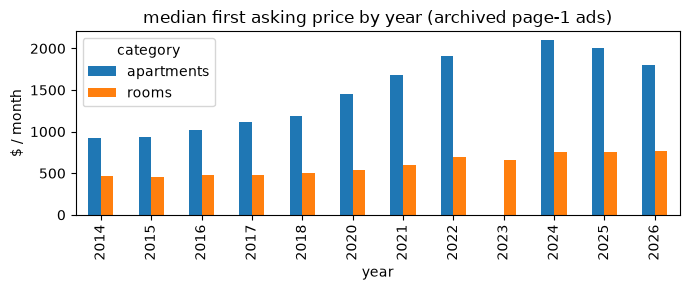

In [9]:
arch = pd.read_sql_query(
    "SELECT substr(first_seen, 1, 4) AS year, category, COUNT(*) AS ads,"
    " ROUND(AVG(first_price)) AS mean_price FROM archive_listings"
    " WHERE first_price IS NOT NULL GROUP BY 1, 2 ORDER BY 1, 2", conn)
med = pd.read_sql_query(
    "SELECT substr(first_seen, 1, 4) AS year, category, first_price FROM archive_listings"
    " WHERE first_price IS NOT NULL", conn)
table = med.groupby(["year", "category"])["first_price"].agg(["count", "median"]).round(0)
print(table)
piv = med.groupby(["year", "category"])["first_price"].median().unstack()
ax = piv.plot.bar(figsize=(7, 3), title="median first asking price by year (archived page-1 ads)")
ax.set_ylabel("$ / month"); plt.tight_layout()

## Volume over time (live sweep)

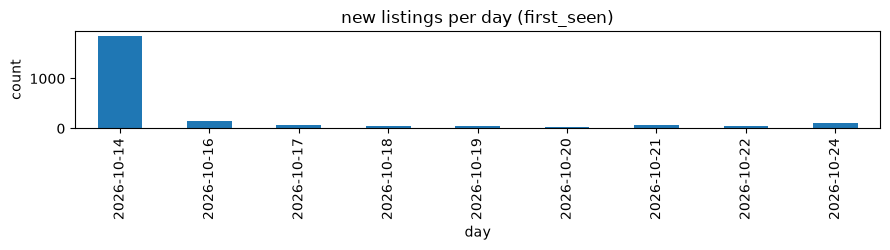

In [10]:
days = pd.read_sql_query(
    "SELECT substr(first_seen, 1, 10) AS day, COUNT(*) AS new_listings FROM listings GROUP BY 1", conn)
ax = days.set_index("day").plot.bar(figsize=(9, 2.6), legend=False, title="new listings per day (first_seen)")
ax.set_ylabel("count"); plt.tight_layout()

## Baselines (recorded 2026-10-24, docs/decisions.md)

Grouped 5-fold CV by `dedup_key`: **lookup MAE $158 ± 11 (MAPE 15.7%)**, **ridge MAE $144 ± 9
(MAPE 14.2%)**; time split (newest 24%): lookup $174, ridge $145. The cell below re-runs them
(about a minute).

In [11]:
from housing.model.baseline import fit_predict_lookup, fit_predict_ridge
from housing.model.evaluate import grouped_cv, summarize

for name, fp in (("lookup", fit_predict_lookup), ("ridge", fit_predict_ridge)):
    print(summarize(name, grouped_cv(df, fp, n_splits=5)))
conn.close()

lookup: MAE $158 ± 11, MAPE 15.7% (n=1862)
ridge: MAE $144 ± 9, MAPE 14.2% (n=1862)
